# 13 — Familia F8: supervisados (D16 logit L1 · D17 random forest)

Dos detectores **supervisados** de la Fase 2 ([ADR-010](../docs/decisions/ADR-010-preregistro-pool-crudo.md) §3):

| id | modelo | hiperparámetros (fijos, sin afinar con crisis) |
|---|---|---|
| D16 | logit con penalización L1 | `C = 1`, `class_weight = "balanced"`, `liblinear`; crisis si p ≥ 0,5 |
| D17 | random forest | 500 árboles, `max_depth = 5`, `min_samples_leaf = 50`, `balanced_subsample`, semilla 42; crisis si p ≥ 0,5 |

Cada uno en dos menús: **P** (pool completo, la variante principal, con la regla de disponibilidad del §2.1) y **N**
(núcleo, la comparación barata; antes era T, descartado en el ADR-009). Mismo walk-forward que v2, paso 21.

**Etiquetas sin fuga (§3.2).** En cada reajuste solo existen como etiqueta las crisis cuyo suelo ya ha pasado; los
días de una crisis aún sin terminar cuentan como calma, igual que los vería alguien en tiempo real. Las trampas
cuentan como calma. La sensibilidad `-excl` saca esos días del ajuste; no pesa en ningún veredicto.

**Categoría aparte (§6, «techo»).** Usan las etiquetas que el resto solo ve para puntuar, así que no entran en el
ranking principal ni en el criterio del §5. Responden otra pregunta: **¿hay en los datos información que los no
supervisados no extraen?**

**Índice**

1. Estado de los resultados
2. Etiquetas en cada reajuste
3. Detección: D16 y D17 en P y en N
4. Techo: frente al mejor no supervisado (§6)
5. Sensibilidad `-excl`
6. Coeficientes e importancias (ilustrativo)
7. Lectura

Solo lee `results/detectores/pool/` (lo escriben `python -m regimenes.benchmark.pool ejecutar` y `leer`). Si falta
algo, cada celda avisa y no falla. Siguiente: `14_comparativa` §8.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'font.size': 9,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 200)

from regimenes import rutas
from regimenes.benchmark import pool_lectura as pl

PISTAS = ('A', 'B')
IDS_SUP = ['D16-P', 'D16-N', 'D17-P', 'D17-N', 'D16-P-excl', 'D17-P-excl']
print('Resultados en', pl.rel(pl.SALIDA))

Resultados en results/detectores/pool


## 1. Estado de los resultados

In [2]:
display(pl.estado())
VAR = pl.variantes()
SUP = VAR[VAR['id'].isin(IDS_SUP)].copy() if len(VAR) else VAR
HAY_SUP = len(SUP) > 0
faltan = [f'{t}/{i}' for t in PISTAS for i in IDS_SUP if not ((SUP['pista'] == t) & (SUP['id'] == i)).any()] \
    if HAY_SUP else [f'{t}/{i}' for t in PISTAS for i in IDS_SUP]
print(f'Supervisados terminados: {len(SUP)} de {2 * len(IDS_SUP)}.',
      f'AVISO: faltan {faltan}; las tablas son PROVISIONALES.' if faltan else '')

,pista,hechos,esperados,pendientes
0,A,9,9,
1,B,11,11,


Supervisados terminados: 12 de 12. 


## 2. Etiquetas en cada reajuste

Crisis terminadas y días de crisis que ve cada reajuste. Mientras no hay ninguna crisis terminada el detector
predice calma (`sup_siempre_calma`).

In [3]:
filas = []
for t in PISTAS:
    for i in ('D16-P', 'D16-N', 'D16-P-excl'):
        r = pl.reajustes(t, i)
        if r.empty or 'sup_n_crisis_terminadas' not in r:
            continue
        calma = r['sup_siempre_calma'].eq(True)
        filas.append({'pista': t, 'id': i, 'reajustes': len(r), 'siempre_calma': int(calma.sum()),
                      'crisis_terminadas_inicio': int(r['sup_n_crisis_terminadas'].iloc[0]),
                      'crisis_terminadas_final': int(r['sup_n_crisis_terminadas'].iloc[-1]),
                      'dias_crisis_final': int(r['sup_n_dias_crisis'].iloc[-1]),
                      'filas_ajuste_final': int(r['sup_n_filas_ajuste'].iloc[-1])})
if filas:
    display(pd.DataFrame(filas).set_index(['pista', 'id']))
    print('Las etiquetas son las mismas en D16 y D17 (mismo menú y misma regla); se muestra D16.')
else:
    print(f'{pl.PENDIENTE}: faltan los reajustes de D16 (reajustes/<P>_D16-*.csv).')

reajustes  siempre_calma  crisis_terminadas_inicio  crisis_terminadas_final  dias_crisis_final  filas_ajuste_final
pista id                                                                                                                            
A     D16-P             673              0                         1                       18               2853               14224
      D16-N             673              0                         1                       18               3268               16128
      D16-P-excl        673              0                         1                       18               2853               14224
B     D16-P             194              0                         1                       10               1057                4749
      D16-N             194              0                         1                       10               1057                4809
      D16-P-excl        194              0                         1                       10               1057                4749

Las etiquetas son las mismas en D16 y D17 (mismo menú y misma regla); se muestra D16.


## 3. Detección: D16 y D17 en P y en N

`score_deteccion` (ADR-003) con recall por evento y precisión. `delta_P_menos_N` dice si el pool completo ayuda a
cada modelo frente al núcleo.

In [4]:
COLS = ['menu', 'score_deteccion', 'det_event_recall', 'det_precision', 'det_lift_precision',
        'det_marked_rate', 'mean_regime_duration', 'n_reajustes']
PRINCIPALES = SUP[~SUP['id'].str.endswith('-excl')] if HAY_SUP else SUP
if len(PRINCIPALES):
    display(PRINCIPALES.set_index(['pista', 'id'])[[c for c in COLS if c in PRINCIPALES]].round(3))
    s = PRINCIPALES.set_index(['pista', 'base', 'menu'])['score_deteccion'].unstack('menu')
    if {'P', 'N'} <= set(s.columns):
        s['delta_P_menos_N'] = s['P'] - s['N']
    display(s.round(3))
else:
    print(f'{pl.PENDIENTE}: D16 y D17 en P y N.')

menu  score_deteccion  det_event_recall  det_precision  det_lift_precision  det_marked_rate  mean_regime_duration  n_reajustes
pista id                                                                                                                                  
A     D16-N    N            0.498             0.765          0.369               1.901            0.267                16.189          673
      D16-P    P            0.189             0.412          0.122               0.630            0.100                25.980          673
      D17-N    N            0.456             0.588          0.372               1.917            0.169                41.690          673
      D17-P    P            0.058             0.118          0.039               0.199            0.046               178.899          673
B     D16-N    N            0.441             0.667          0.330               1.909            0.155                18.040          194
      D16-P    P            0.142             0.333          0.090               0.523            0.068                30.067          194
      D17-N    N            0.414             0.667          0.300               1.736            0.127                29.628          194
      D17-P    P            0.057             0.111          0.038               0.220            0.045               130.935          194

menu            N      P  delta_P_menos_N
pista base                               
A     D16   0.498  0.189           -0.309
      D17   0.456  0.058           -0.397
B     D16   0.441  0.142           -0.299
      D17   0.414  0.057           -0.357

## 4. Techo: frente al mejor no supervisado (§6)

Cada supervisado frente al mejor no supervisado de su pista (los 12 de v2 y las variantes no supervisadas del pool
terminadas), con `score_deteccion`, y su presencia en un MCS de supervisados y no supervisados juntos, solo como
lectura. Si ninguno mejora al mejor no supervisado, ni con etiquetas se gana a lo simple; si alguno lo mejora, hay
información que los no supervisados no extraen. En ningún caso cambia el ranking principal.

In [5]:
TECHO = pl.leer_tabla('techo_supervisados')
aviso = pl.aviso_tabla('techo_supervisados.csv', TECHO)
if TECHO is None or TECHO.attrs.get('desfasada'):
    print(aviso, 'Se muestra el score sin MCS, calculado con lo terminado.')
    TECHO = pl.techo()
if len(TECHO):
    display(TECHO.set_index(['pista', 'id']).round(3))
    print('Mejoran al mejor no supervisado:', list(TECHO.loc[TECHO['mejora_al_mejor'], 'id']
                                                   + '/' + TECHO.loc[TECHO['mejora_al_mejor'], 'pista']) or 'ninguno')
    if 'en_mcs_conjunto' in TECHO:
        print('En el MCS conjunto:', [f'{r.pista}/{r.id}' for r in TECHO.itertuples() if r.en_mcs_conjunto] or 'ninguno')
else:
    print(f'{pl.PENDIENTE}: techo de los supervisados.')
for t in PISTAS:
    MCS_SUP = pl.leer_tabla(f'mcs_supervisados_{t}', index_col='modelo')
    if MCS_SUP is None:
        print(pl.aviso_tabla(f'mcs_supervisados_{t}.csv', MCS_SUP))
        continue
    dentro = [str(i) for i in MCS_SUP.index[MCS_SUP['incluido'].astype(bool)]]
    print(f'Pista {t} · MCS conjunto al 10 % (bloque {MCS_SUP["bloque"].iloc[0]}): mejor {MCS_SUP["perdida_media"].idxmin()}; '
          f'dentro {dentro}', pl.aviso_tabla('', MCS_SUP) or '')

score mejor_no_supervisado  score_mejor  mejora_al_mejor  en_mcs_conjunto
pista id                                                                                   
A     D16-N       0.498                  D10        0.614            False             True
      D16-P-excl  0.397                  D10        0.614            False            False
      D16-P       0.189                  D10        0.614            False            False
      D17-N       0.456                  D10        0.614            False             True
      D17-P-excl  0.252                  D10        0.614            False            False
      D17-P       0.058                  D10        0.614            False            False
B     D16-N       0.441                  D05        0.647            False             True
      D16-P-excl  0.286                  D05        0.647            False             True
      D16-P       0.142                  D05        0.647            False            False
      D17-N       0.414                  D05        0.647            False             True
      D17-P-excl  0.392                  D05        0.647            False             True
      D17-P       0.057                  D05        0.647            False            False

Mejoran al mejor no supervisado: ninguno
En el MCS conjunto: ['A/D16-N', 'A/D17-N', 'B/D16-N', 'B/D16-P-excl', 'B/D17-N', 'B/D17-P-excl']
Pista A · MCS conjunto al 10 % (bloque 66): mejor D06; dentro ['D06', 'D05', 'D01', 'D10', 'D12', 'VOL_P90', 'D15-U', 'D03', 'D04', 'D02', 'D18-P', 'D16-N', 'D08', 'D07', 'D11', 'D17-N'] 
Pista B · MCS conjunto al 10 % (bloque 50): mejor D05; dentro ['D05', 'D06', 'D10', 'D15-U', 'D04', 'D11', 'D02', 'D10-R', 'D07', 'D17-N', 'D01', 'D16-N', 'D14-R', 'D10-P', 'D17-P-excl', 'D18-P', 'D12', 'D16-P-excl', 'VOL_P90'] 


## 5. Sensibilidad `-excl`

La variante que saca del ajuste los días de crisis aún sin terminar, frente a la principal en P. Sin peso en el
veredicto: elige las filas con una etiqueta futura (§3.2).

In [6]:
if HAY_SUP:
    s = SUP.set_index(['pista', 'id'])['score_deteccion']
    filas = [{'pista': t, 'modelo': b, 'principal': s.get((t, f'{b}-P')), 'excl': s.get((t, f'{b}-P-excl'))}
             for t in PISTAS for b in ('D16', 'D17')]
    EXCL = pd.DataFrame(filas).dropna(subset=['principal', 'excl'], how='all')
    EXCL['delta_excl_menos_principal'] = EXCL['excl'] - EXCL['principal']
    if len(EXCL):
        display(EXCL.set_index(['pista', 'modelo']).round(3))
    else:
        print(f'{pl.PENDIENTE}: sensibilidad -excl (faltan D16-P/D17-P y sus -excl).')
else:
    print(f'{pl.PENDIENTE}: sensibilidad -excl.')

principal   excl  delta_excl_menos_principal
pista modelo                                              
A     D16         0.189  0.397                       0.208
      D17         0.058  0.252                       0.194
B     D16         0.142  0.286                       0.144
      D17         0.057  0.392                       0.336

## 6. Coeficientes e importancias (ilustrativo)

Del ajuste final con toda la muestra (todas las crisis terminadas), el mismo que hace el ejecutor al terminar; no
son los modelos de cada reajuste. D16: coeficientes del logit sobre z-scores (L1 deja muchos a 0). D17: importancia
por reducción de impureza. Se calcula solo para las variantes terminadas; el random forest tarda unos segundos.

A/D16-P: 34 de 35 coeficientes distintos de 0.
A/D16-N: 9 de 9 coeficientes distintos de 0.
B/D16-P: 65 de 77 coeficientes distintos de 0.
B/D16-N: 14 de 14 coeficientes distintos de 0.


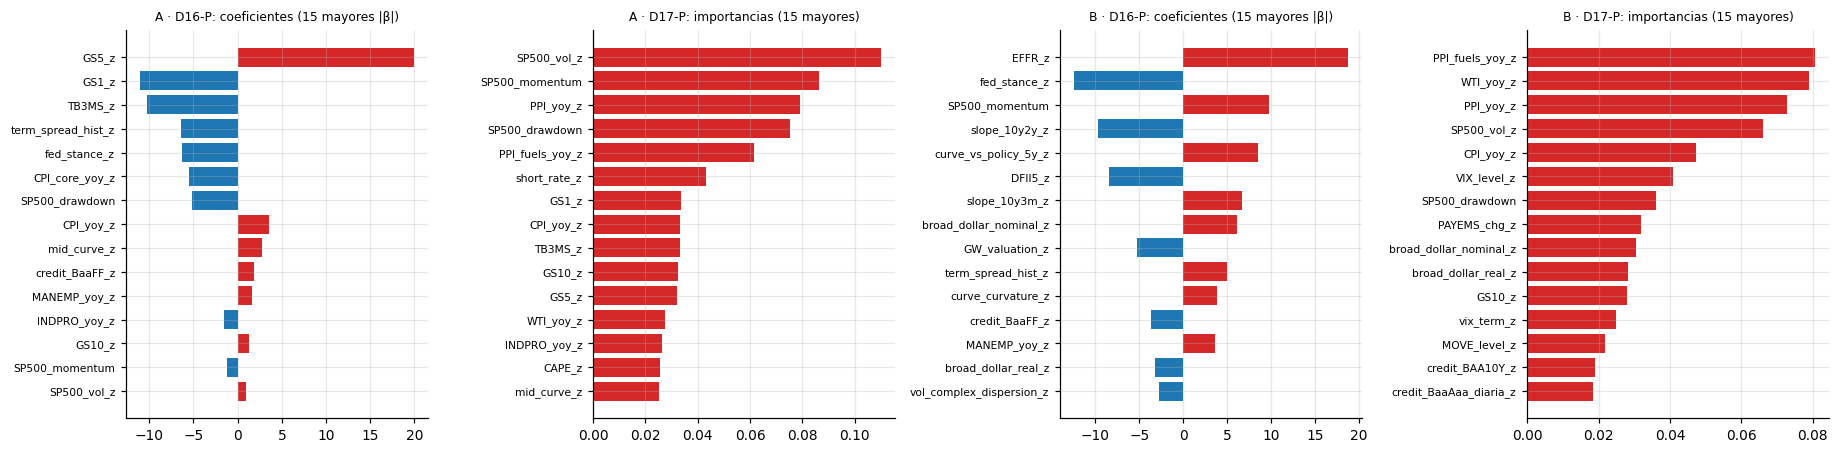

,A/D16-N,A/D17-N,B/D16-N,B/D17-N
DFII10_change_z,NaN,NaN,0.199,0.002
DGS10_change_z,0.015,0.003,-0.171,0.001
FF_MKT_z,-0.953,0.023,-0.533,0.009
INDPRO_yoy_z,0.598,0.100,1.286,0.098
MOVE_level_z,NaN,NaN,1.186,0.105
SP500_drawdown,-0.565,0.253,10.902,0.119
SP500_momentum,-4.242,0.178,-2.547,0.044
SP500_ret_z,0.765,0.008,0.350,0.009
SP500_vol_z,1.129,0.181,0.429,0.191
VIX_level_z,NaN,NaN,0.933,0.137


In [7]:
CALCULAR_IMPORTANCIAS = True
IMP = {}
if CALCULAR_IMPORTANCIAS and HAY_SUP:
    for t in PISTAS:
        for i in ('D16-P', 'D17-P', 'D16-N', 'D17-N'):
            if ((SUP['pista'] == t) & (SUP['id'] == i)).any():
                imp = pl.importancias(t, i)
                if imp is not None:
                    IMP[t, i] = imp
if IMP:
    for (t, i), v in IMP.items():
        if i.startswith('D16'):
            print(f'{t}/{i}: {int((v != 0).sum())} de {len(v)} coeficientes distintos de 0.')
    principales = [(t, i) for (t, i) in IMP if i.endswith('-P')]
    if principales:
        fig, axes = plt.subplots(1, len(principales), figsize=(4.2 * len(principales), 4.2), squeeze=False)
        for ax, (t, i) in zip(axes[0], principales):
            v = IMP[t, i]
            top = v.reindex(v.abs().sort_values().index[-15:])
            ax.barh(top.index, top.to_numpy(), color=np.where(top.to_numpy() >= 0, 'C3', 'C0'))
            ax.set_title(f'{t} · {i}: ' + ('coeficientes (15 mayores |β|)' if i.startswith('D16') else 'importancias (15 mayores)'),
                         fontsize=8)
            ax.tick_params(axis='y', labelsize=7)
        plt.tight_layout()
        plt.show()
    N_TAB = {f'{t}/{i}': v for (t, i), v in IMP.items() if i.endswith('-N')}
    if N_TAB:
        display(pd.DataFrame(N_TAB).round(3))
else:
    print(f'{pl.PENDIENTE}: coeficientes e importancias (faltan las variantes o la entrada de pool preparar).')

## 7. Lectura

Cifras del 03-11-2026 (ADR-010 §9):

- **D16 y D17 en P frente a N:** con el pool rinden mucho peor.

  | Pista | Modelo | Score con P | Score con N |
  |---|---|---|---|
  | A | D16 | 0,189 | 0,498 |
  | A | D17 | 0,058 | 0,456 |
  | B | D16 | 0,142 | 0,441 |
  | B | D17 | 0,057 | 0,414 |

  Con 35 o 77 columnas y solo 18 (A) o 10 (B) crisis terminadas, sobreajustan. D17-P apenas marca nada: el 4,6 %
  de los días, con regímenes de 179 días de media.
- **Techo (§6):** ninguno mejora al mejor no supervisado (D10 con 0,614 en A; D05 con 0,647 en B). En el MCS
  conjunto entran D16-N y D17-N en las dos pistas, y las variantes `-excl` solo en B. Ni con etiquetas se gana a lo
  simple.
- **Sensibilidad `-excl`:** mejora a la P principal entre +0,14 y +0,34, pero sigue por debajo de N.
- **Qué columnas usan:**
  - **D16-P apenas es disperso:** L1 con C = 1 deja 34 de 35 coeficientes distintos de 0 en A y 65 de 77 en B.
  - **En N pesan sobre todo:** el momentum del SP500 en A (−4,2) y su drawdown en B (+10,9).